# SMOTEFUNA
**Synthetic Minority Over-Sampling Technique Based on Furthest Neighbour Algorithm**

Tarawneh, Hassanat, Almohammadi, Chetverikov, Bellinger — *IEEE Access*, 2020

This notebook is the live version of the 5-slide talk:
1. Introduction  
2. Proposed idea  
3. Algorithm  
4. Live demo + saved benchmark  
5. Conclusion

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

ROOT = Path.cwd().resolve()
if (ROOT / "smotefuna").exists():
    pass
elif (ROOT.parent / "smotefuna").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from smotefuna import SMOTEFUNA
from experiments.baselines import SMOTEBaseline

RESULTS_REAL = ROOT / "experiments" / "results_real"
RESULTS_GEN = ROOT / "experiments" / "results"
RESULTS = RESULTS_REAL if (RESULTS_REAL / "tables" / "table2_wins.csv").exists() else RESULTS_GEN
print("Project root:", ROOT)
print("Showing results from:", RESULTS.relative_to(ROOT))

Project root: C:\Users\chara\Desktop\SMOTE
Showing results from: experiments\results_real


## 1. Introduction — class imbalance

A dataset is imbalanced when one class is much smaller than another:

$$|C_i| \ll |C_j|$$

Standard classifiers then bias toward the majority. The minority class is often the important one (fraud, disease, failure).

**Usual fixes:** collect more data, cost-sensitive learning, or **synthetic oversampling** (SMOTE family).

**Gap:** SMOTE needs a neighbour count $K$, fills only a *line* between near neighbours, and can copy clusters / spill into majority space.

## 2. Proposed idea

SMOTEFUNA is **parameter-free**:

1. Pick a random minority seed $S_1$
2. Find its **furthest** minority neighbour $S_2$ (Manhattan distance)
3. Draw each feature inside the cuboid between them:

$$S^{\mathrm{new}}_j = \mathrm{Random}\big(\min(S_{1j}, S_{2j}),\, \max(S_{1j}, S_{2j})\big)$$

4. Keep the point only if it is closer to minority than majority: $\theta \le \beta$

| SMOTE | SMOTEFUNA |
|---|---|
| $k$ nearest neighbours | furthest neighbour |
| needs $K$ | no $K$ |
| line interpolation | cuboid fill |
| near-replicas | more diversity |

## 3. Algorithm — run it on a small 2D set

Live demo only (not the 33-dataset job). Majority vs rare minority, two features so we can plot.

In [2]:
X, y = make_classification(
    n_samples=400,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.9, 0.1],
    class_sep=1.4,
    random_state=42,
)
print(f"Original  majority={np.sum(y == 0)}  minority={np.sum(y == 1)}")

sampler = SMOTEFUNA(random_state=42, shuffle=False)
X_fun, y_fun = sampler.fit_resample(X, y)
print(f"SMOTEFUNA majority={np.sum(y_fun == 0)}  minority={np.sum(y_fun == 1)}")

smote = SMOTEBaseline(k_neighbors=5, random_state=42)
X_sm, y_sm = smote.fit_resample(X, y)
print(f"SMOTE     majority={np.sum(y_sm == 0)}  minority={np.sum(y_sm == 1)}")

Original  majority=359  minority=41
SMOTEFUNA majority=359  minority=359
SMOTE     majority=359  minority=359


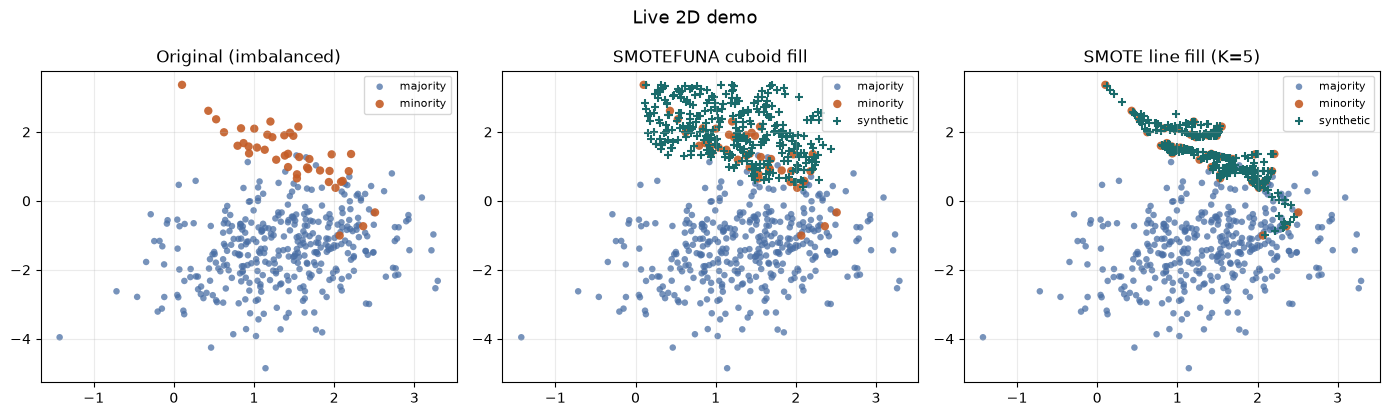

In [3]:
def scatter_classes(ax, X_, y_, title, synthetics=None):
    ax.scatter(X_[y_ == 0, 0], X_[y_ == 0, 1], c="#4A6FA5", s=22, alpha=0.75, label="majority", edgecolors="none")
    ax.scatter(X_[y_ == 1, 0], X_[y_ == 1, 1], c="#C45C26", s=36, alpha=0.9, label="minority", edgecolors="none")
    if synthetics is not None and len(synthetics):
        ax.scatter(synthetics[:, 0], synthetics[:, 1], c="#1A6B6B", marker="+", s=40, label="synthetic")
    ax.set_title(title)
    ax.legend(loc="best", fontsize=8)
    ax.grid(True, alpha=0.25)

synth_fun = X_fun[len(X):]
synth_sm = X_sm[len(X):]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
scatter_classes(axes[0], X, y, "Original (imbalanced)")
scatter_classes(axes[1], X, y, "SMOTEFUNA cuboid fill", synthetics=synth_fun)
scatter_classes(axes[2], X, y, "SMOTE line fill (K=5)", synthetics=synth_sm)
fig.suptitle("Live 2D demo", fontsize=13)
fig.tight_layout()
plt.show()

Quick check: train SVM on original vs SMOTEFUNA-balanced training data, test on the **same untouched** hold-out split.

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_tr_fun, y_tr_fun = SMOTEFUNA(random_state=0).fit_resample(X_tr, y_tr)
X_tr_sm, y_tr_sm = SMOTEBaseline(random_state=0).fit_resample(X_tr, y_tr)

def auc_of(X_train, y_train):
    clf = SVC(probability=True, random_state=0)
    clf.fit(X_train, y_train)
    return roc_auc_score(y_te, clf.predict_proba(X_te)[:, 1])

print(f"SVM AUC  original  = {auc_of(X_tr, y_tr):.3f}")
print(f"SVM AUC  SMOTE     = {auc_of(X_tr_sm, y_tr_sm):.3f}")
print(f"SVM AUC  SMOTEFUNA = {auc_of(X_tr_fun, y_tr_fun):.3f}")

SVM AUC  original  = 0.995
SVM AUC  SMOTE     = 0.986
SVM AUC  SMOTEFUNA = 0.992


c:\Users\chara\anaconda3\envs\big_data\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\chara\anaconda3\envs\big_data\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\chara\anaconda3\envs\big_data\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 4. Results

### Paper (what to say on the slides)
33 binary KEEL/PROMISE datasets, 5-fold CV × 30 trials, Naive Bayes and SVM, vs SMOTE, ADASYN, SWIM, and original data.

Authors report SMOTEFUNA wins most datasets on AUC and AUPR, with Wilcoxon $p < 0.05$ in its favour, and **no $K$ to tune**.

### Our replication (`experiments/results_real/`)
Pulled from `master`: OpenML/KEEL-style tables, 33 datasets. Closer to the paper than the generated stand-ins in `experiments/results/`.

Still **not** the paper’s 30-trial MATLAB protocol. On this run SMOTEFUNA is competitive (e.g. 9 SVM-AUC wins, tied with SMOTE) but **SWIM / original still win more often** — so quote the paper’s Table 2 on slides, and use these plots as *our implementation*.

In [5]:
wins = pd.read_csv(RESULTS / "tables" / "table2_wins.csv")
pval = pd.read_csv(RESULTS / "tables" / "table3_wilcoxon_pvalues.csv")
display(Markdown(f"**Table 2 — wins** ({RESULTS.name})"))
display(wins)
display(Markdown("**Table 3 — Wilcoxon p-values, SMOTEFUNA vs others**"))
display(pval)

**Table 2 — wins** (results_real)

,Classifier,Measure,SMOTEFUNA,SMOTE,ADASYN,SWIM,Original
0,NB,AUC,5,6,7,9,8
1,SVM,AUC,9,9,8,14,7
2,NB,AUPR,7,11,4,4,9
3,SVM,AUPR,7,8,7,6,18


**Table 3 — Wilcoxon p-values, SMOTEFUNA vs others**

,Measure,Classifier,SMOTE,ADASYN,SWIM,Original
0,AUC,SVM,0.0189,0.0577,0.000789,0.8590
1,AUC,NB,0.0602,0.0606,0.010700,0.0049
2,AUPR,SVM,0.3450,0.7577,0.055300,0.0027
3,AUPR,NB,0.0119,0.0529,0.114700,0.0553


**Figure 9 — ROC / PR (Naive Bayes)**

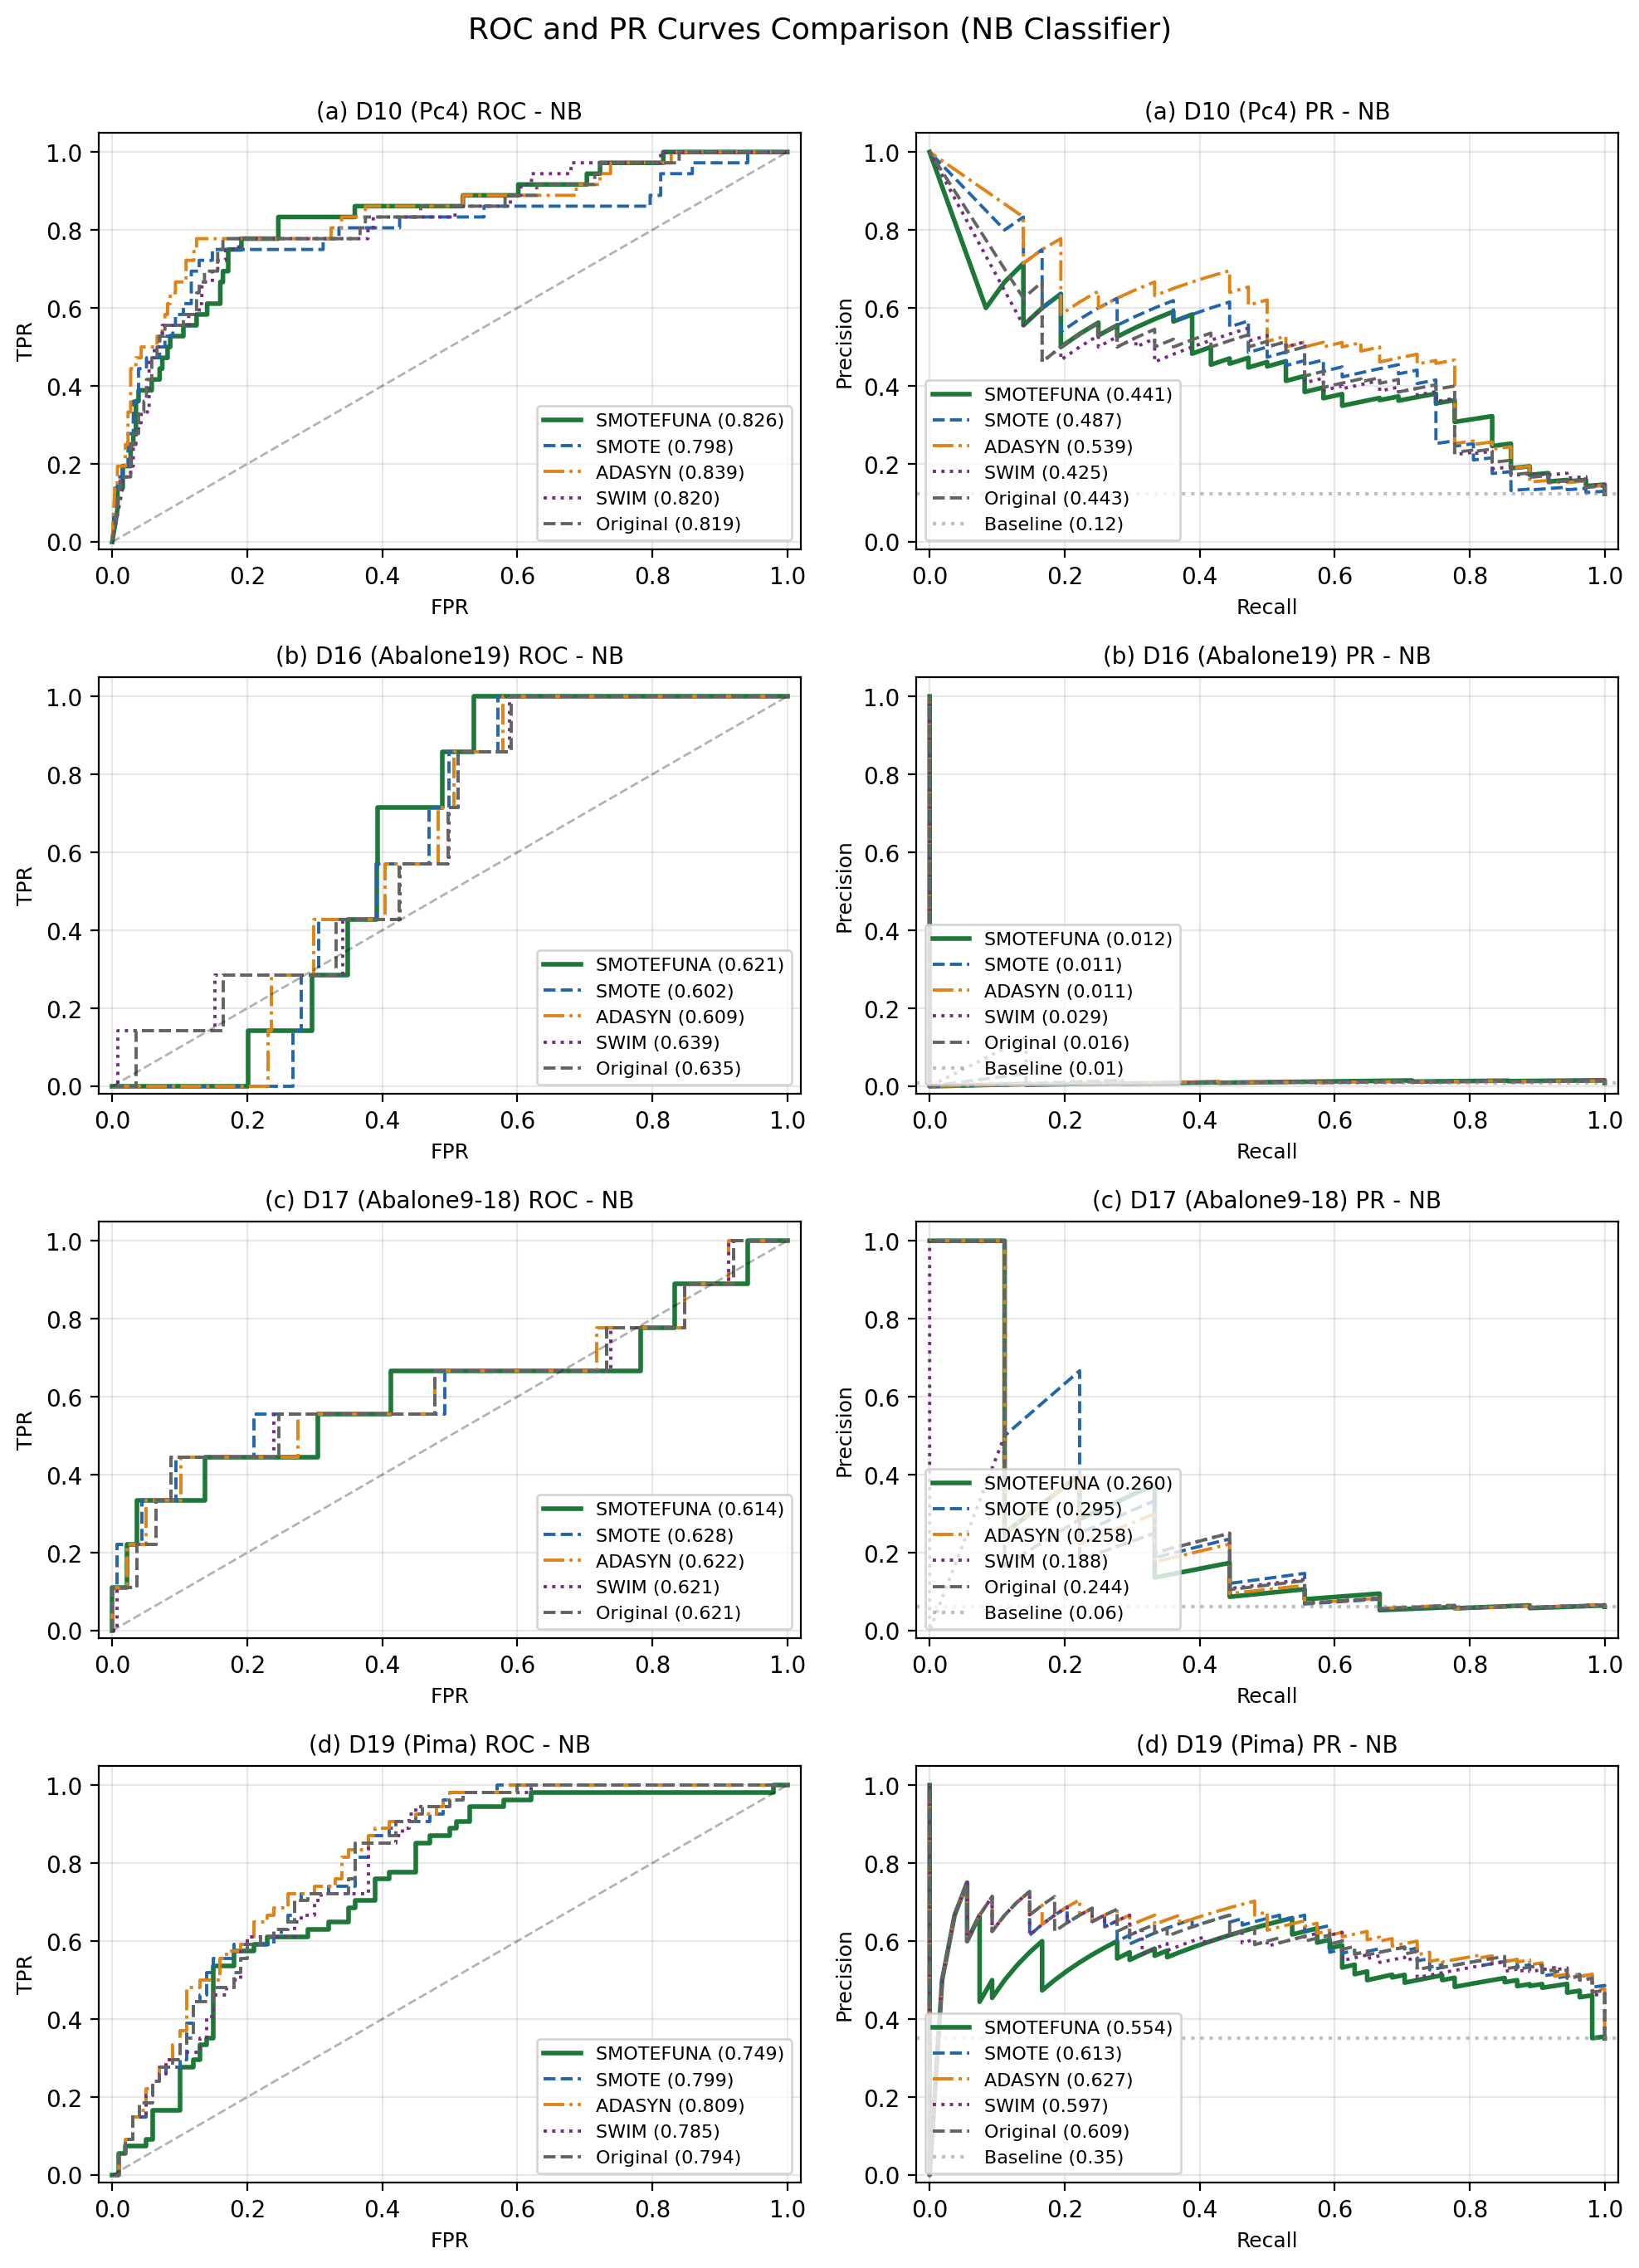

**Figure 10 — ROC / PR (SVM)**

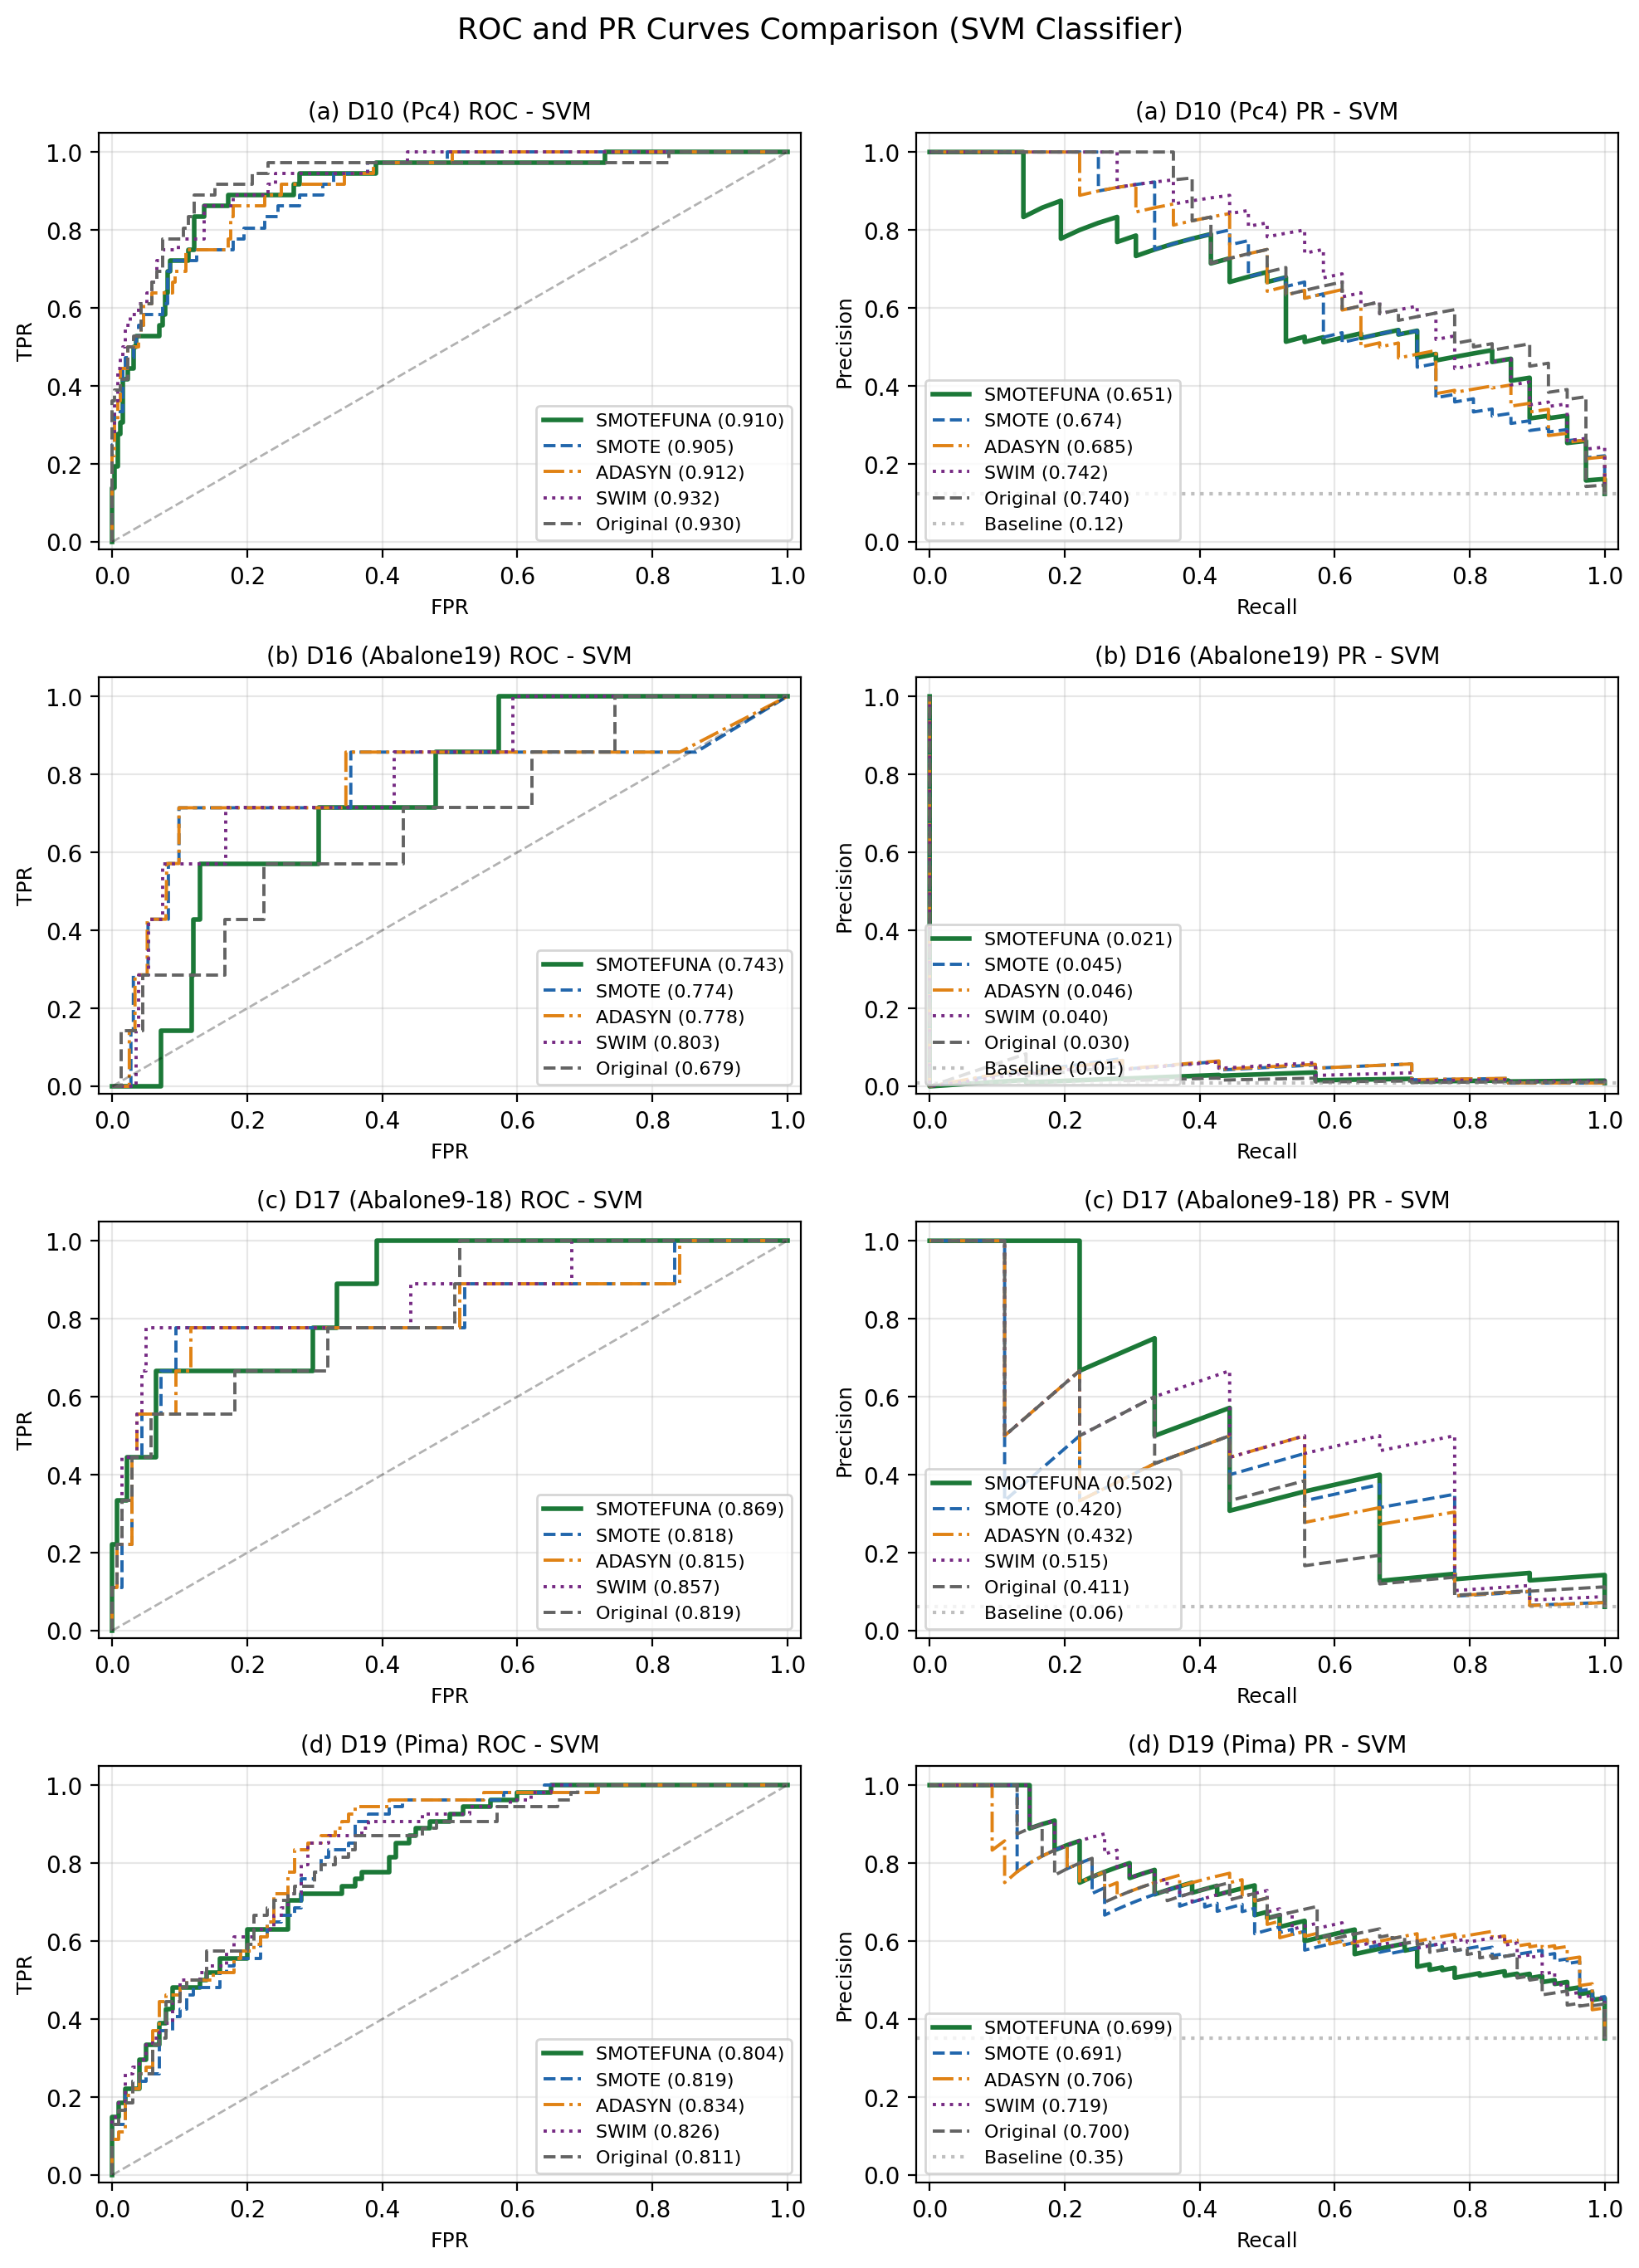

**Figure 8 — PCA of majority, minority, synthetics**

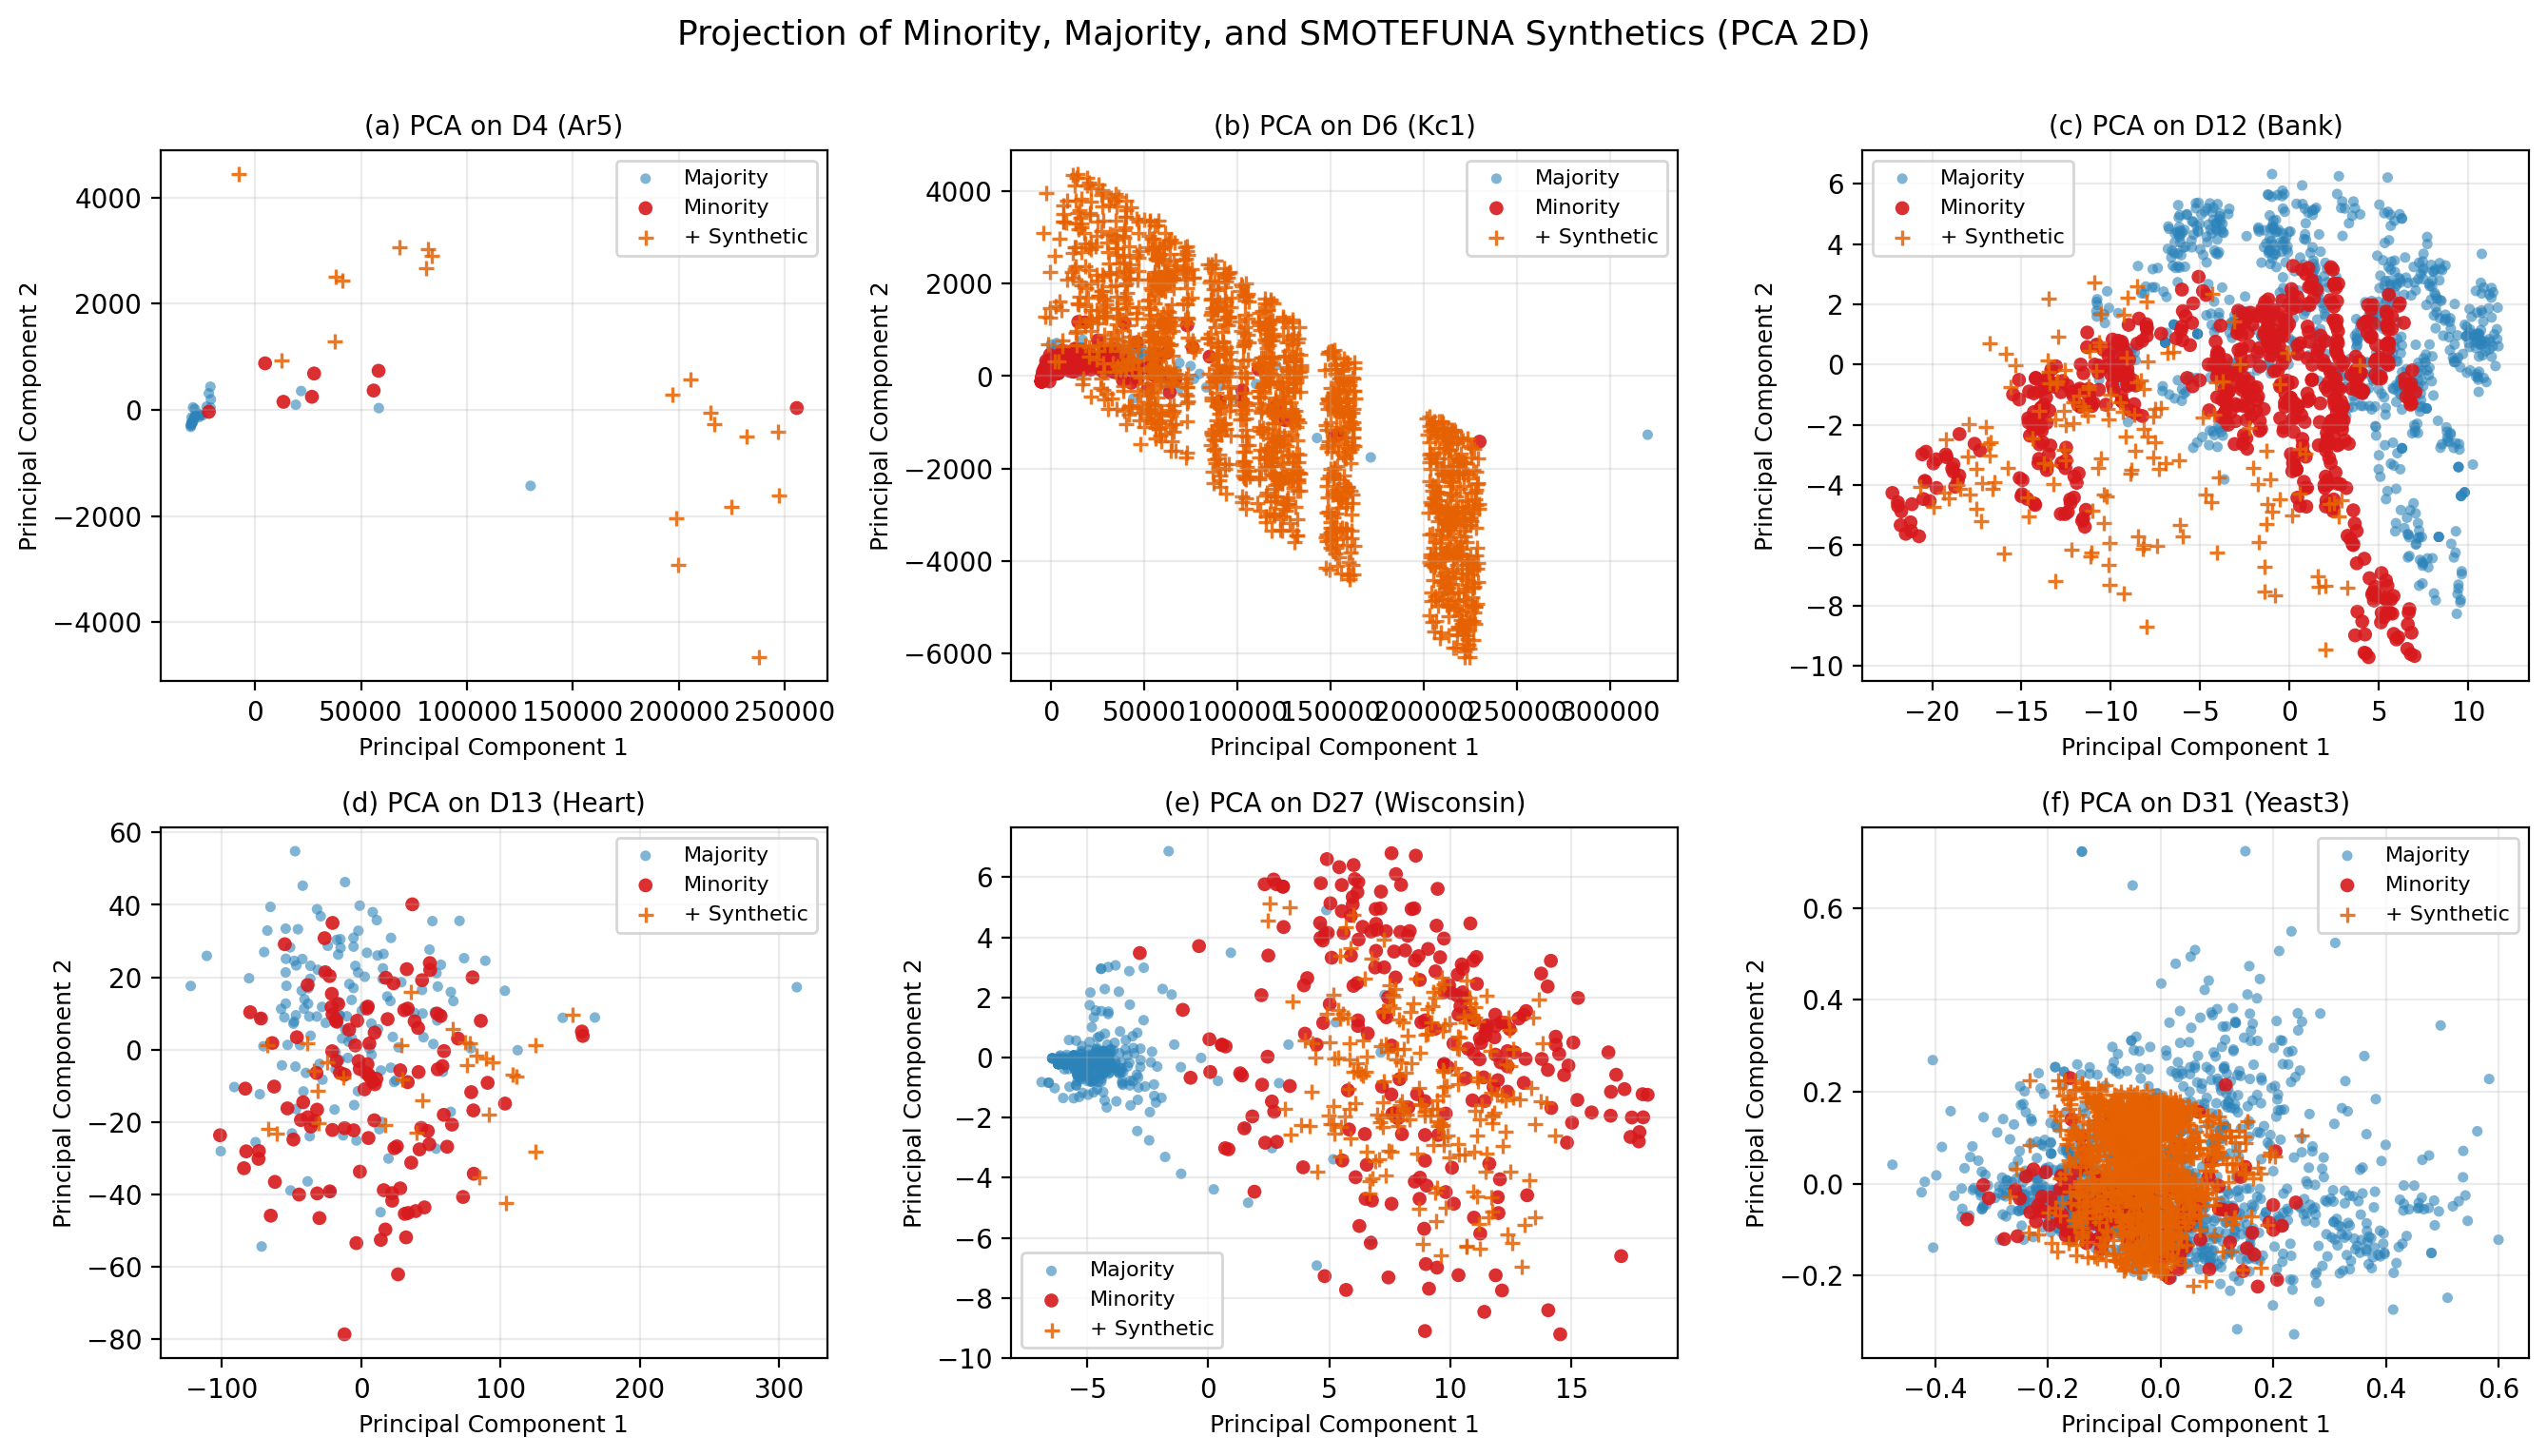

In [6]:
for name, caption in [
    ("fig9_nb_roc_pr_curves.png", "Figure 9 — ROC / PR (Naive Bayes)"),
    ("fig10_svm_roc_pr_curves.png", "Figure 10 — ROC / PR (SVM)"),
    ("fig8_pca_projections.png", "Figure 8 — PCA of majority, minority, synthetics"),
]:
    path = RESULTS / "figures" / name
    display(Markdown(f"**{caption}**"))
    if path.exists():
        display(Image(filename=str(path), width=900))
    else:
        print("Missing", path)

## 5. Conclusion, limitations, future work

**Conclusion (paper):** parameter-free furthest-neighbour oversampling with a nearest-neighbour safety check; reported as a practical alternative to SMOTE / ADASYN / SWIM.

**Limitations:** isolated minority outliers can pull the cuboid away from the true boundary; current paper study is binary classification.

**Future work (paper):** outlier removal or robust distances; multi-class, nominal, and large data; more baselines.

**Our code:** `from smotefuna import SMOTEFUNA` then `fit_resample(X, y)`. Full benchmark stays in `python experiments/run_experiments.py` — not in this notebook.